# 15 — Positive predictive value and decisions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/15_ppv_and_decisions.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

A positive classification and a justified action answer different questions. First, count how many positive results are expected to be true in a population. Then specify the consequences of two possible actions. The paper's example uses 10,000 hypothetical people, 1% prevalence, 90% sensitivity and 90% specificity. We reproduce its counts and PPV curve before examining its simplified cost model.

All numbers are stipulated teaching inputs. No diagnostic model is fitted and no patient data are used. Expected counts can be fractional when parameters change: they are averages implied by the model, not observed people or a random trial.

### Learning goals

1. Define sensitivity, specificity, prevalence and positive predictive value using their denominators.
2. Derive PPV from expected counts and explain why population size cancels.
3. Distinguish population prevalence, group predictive value and a decision probability.
4. Derive a two-action threshold from explicit costs, including the equal-cost case.
5. Identify which assumptions would need evidence before applying either calculation to imaging or care.


## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

**Condition and positive result.** A condition is the specified target being assessed; a positive result is the classifier's label at a fixed operating threshold. A false positive has a positive label although the target is absent. A false negative has a negative label although the target is present. A biological target and the reference used to label it must be defined in an actual study.

**Sensitivity** divides true positives by all condition-present cases. **Specificity** divides true negatives by all condition-absent cases. **Prevalence** divides condition-present cases by everyone in the population. **Positive predictive value (PPV)** divides true positives by everyone with a positive result. Sensitivity and PPV reverse the conditioning; they need not be equal.

Read the 10,000-person table before the formula. Explain how a large condition-absent group can supply many false positives even when only 10% of that group tests positive. Then ask which population the rates describe.

**Decision cost** assigns a consequence to an action and condition status. Here the two actions are simply “act” and “do not act”; correct actions have zero cost. These invented units do not specify a treatment, patient preference or clinical policy.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

Let $Y=1$ mean condition present and $T=1$ a positive result. Write $\pi=P(Y=1)$, $\mathrm{Se}=P(T=1\mid Y=1)$ and $\mathrm{Sp}=P(T=0\mid Y=0)$. For population size $N$, form the four expected joint counts before conditioning on $T=1$.

The denominator $P(T=1)=\mathrm{Se}\pi+(1-\mathrm{Sp})(1-\pi)$ must be positive to define PPV. A zero denominator means there is no positive-result group to condition on. The code returns `nan` in that case rather than inventing a predictive value.

For decision probability $p=P(Y=1\mid\text{available evidence})$ and positive costs $C_{\mathrm{FP}}, C_{\mathrm{FN}}$, compare $(1-p)C_{\mathrm{FP}}$ with $pC_{\mathrm{FN}}$. The decision boundary follows from their equality. The code reports indifference at equality within numerical roundoff.

Population prevalence $\pi$ and decision probability $p$ have different roles. PPV pools everyone with a positive label. It can serve as a group probability when only that label and the stated population model are used; it is not automatically the risk for each person when additional information is available.

</details>


### Run in Colab or locally

Run the setup cell, then the remaining cells in order on a CPU kernel. Colab obtains the shared repository files and installs NumPy, Matplotlib and ipywidgets, excluding the large presentation. Local use needs this checkout and its project environment. The calculations need no network after setup and use no random seed. Static reference plots are saved below; the live controls require a running kernel. Generated PNGs and the results record go under ignored `.build/paper-examples/15_ppv_and_decisions/`.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8", "ipywidgets>=8.1"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

import math
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
OUTPUT = ROOT / ".build/paper-examples/15_ppv_and_decisions"
OUTPUT.mkdir(parents=True, exist_ok=True)

def show_figure(fig, name):
    fig.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 1. Count before dividing

**Predict first.** Out of 10,000 people, how many have the condition at 1% prevalence? Of those, how many test positive at 90% sensitivity? How many of the remaining people test positive at 90% specificity?

The four counts are

$$\mathrm{TP}=N\pi\mathrm{Se},\quad \mathrm{FN}=N\pi(1-\mathrm{Se}),$$
$$\mathrm{FP}=N(1-\pi)(1-\mathrm{Sp}),\quad \mathrm{TN}=N(1-\pi)\mathrm{Sp}.$$

The functions below accept scalar probabilities between zero and one. Keeping the calculation visible lets you trace each number back to its denominator.


In [2]:
def probability(value, name):
    value = float(value)
    if not math.isfinite(value) or not 0 <= value <= 1:
        raise ValueError(f"{name} must be finite and between 0 and 1")
    return value

def expected_counts(prevalence, sensitivity, specificity, population=10_000):
    pi = probability(prevalence, "prevalence")
    se = probability(sensitivity, "sensitivity")
    sp = probability(specificity, "specificity")
    n = float(population)
    if not math.isfinite(n) or n <= 0:
        raise ValueError("population must be finite and positive")
    return {"TP": n*pi*se, "FN": n*pi*(1-se),
            "FP": n*(1-pi)*(1-sp), "TN": n*(1-pi)*sp}

def positive_predictive_value(counts):
    positives = counts["TP"] + counts["FP"]
    return counts["TP"] / positives if positives > 0 else float("nan")

counts = expected_counts(0.01, 0.9, 0.9)
ppv = positive_predictive_value(counts)
display(Markdown(f"""| Condition status | Positive result | Negative result | Total |
|---|---:|---:|---:|
| Present | {counts['TP']:,.0f} | {counts['FN']:,.0f} | 100 |
| Absent | {counts['FP']:,.0f} | {counts['TN']:,.0f} | 9,900 |
| Total | {counts['TP']+counts['FP']:,.0f} | {counts['FN']+counts['TN']:,.0f} | 10,000 |"""))
print(f"PPV = {counts['TP']:.0f} / ({counts['TP']:.0f} + {counts['FP']:.0f}) = {ppv:.2%}")
np.testing.assert_allclose([counts[k] for k in ("TP", "FN", "FP", "TN")],
                           [90, 10, 990, 8910], rtol=0, atol=1e-10)
assert math.isclose(ppv, 1/12, rel_tol=1e-12)


| Condition status | Positive result | Negative result | Total |
|---|---:|---:|---:|
| Present | 90 | 10 | 100 |
| Absent | 990 | 8,910 | 9,900 |
| Total | 1,080 | 8,920 | 10,000 |

PPV = 90 / (90 + 990) = 8.33%


There are **90 true positives and 990 false positives**, so only 90 of the 1,080 positive results are true: about **8.3%**. Sensitivity is still 90% because it uses the 100 condition-present cases as its denominator. Overall accuracy is also 90% here, but that does not answer the question about positive results.

Divide the true-positive count by all positives and cancel $N$:

$$\mathrm{PPV}=\frac{N\pi\mathrm{Se}}{N\pi\mathrm{Se}+N(1-\pi)(1-\mathrm{Sp})}
=\frac{\pi\mathrm{Se}}{\pi\mathrm{Se}+(1-\pi)(1-\mathrm{Sp})}.$$

Doubling the population size doubles every expected count and leaves this ratio unchanged. The fractional precision of an expected count does not measure the uncertainty of estimated sensitivity, specificity or prevalence.


## 2. Change prevalence while holding test performance fixed

**Predict first.** At 10% prevalence, are true and false positives equally numerous under the same 90% sensitivity and specificity? What happens at 50%?

This controlled comparison keeps the classifier's operating threshold, sensitivity and specificity fixed. In a real transfer between populations, case mix, acquisition and reference labels can change sensitivity and specificity as well. Changing a classifier's operating threshold would also change them; this notebook does not model an ROC curve.


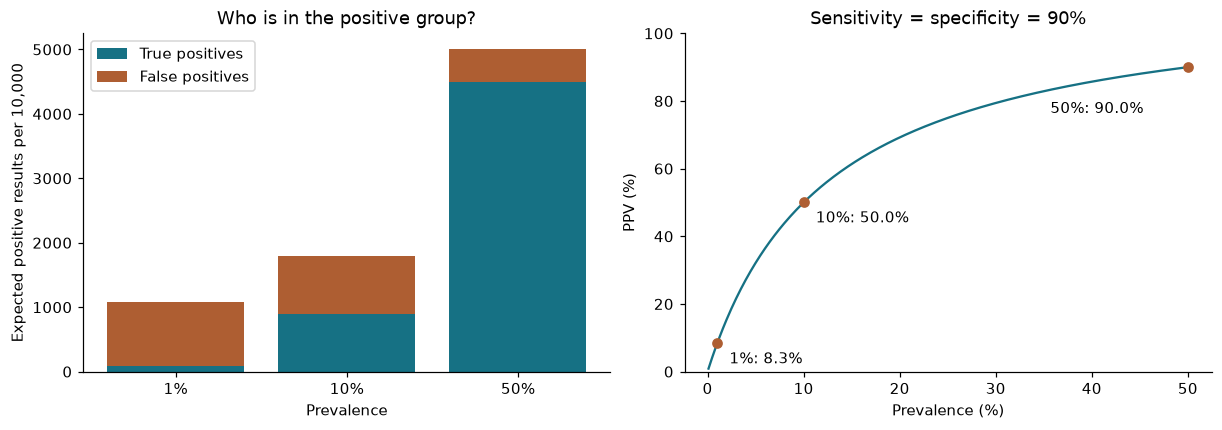

In [3]:
prevalences = np.array([0.01, 0.10, 0.50])
cohorts = [expected_counts(pi, 0.9, 0.9) for pi in prevalences]
ppvs = np.array([positive_predictive_value(c) for c in cohorts])
np.testing.assert_allclose(ppvs, [1/12, 0.5, 0.9], rtol=0, atol=1e-14)
paper_values = json.loads((ROOT / "paper/figures/computed_values.json").read_text())["ppv"]
np.testing.assert_allclose(ppvs, [paper_values[str(pi)] for pi in prevalences], rtol=0, atol=1e-14)

curve_pi = np.linspace(0.001, 0.5, 400)
curve_ppv = [positive_predictive_value(expected_counts(pi, 0.9, 0.9)) for pi in curve_pi]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].bar(range(3), [c["TP"] for c in cohorts], label="True positives", color="#167184")
axes[0].bar(range(3), [c["FP"] for c in cohorts], bottom=[c["TP"] for c in cohorts],
            label="False positives", color="#ae5e32")
axes[0].set(xticks=range(3), xticklabels=["1%", "10%", "50%"], xlabel="Prevalence",
            ylabel="Expected positive results per 10,000", title="Who is in the positive group?")
axes[0].legend()
axes[1].plot(100*curve_pi, 100*np.array(curve_ppv), color="#167184")
axes[1].scatter(100*prevalences, 100*ppvs, color="#ae5e32", zorder=3)
for pi, value in zip(prevalences, ppvs):
    axes[1].annotate(f"{pi:.0%}: {value:.1%}", (100*pi, 100*value),
                     xytext=(8, -13) if pi < 0.5 else (-90, -30), textcoords="offset points")
axes[1].set(xlabel="Prevalence (%)", ylabel="PPV (%)", ylim=(0, 100),
            title="Sensitivity = specificity = 90%")
show_figure(fig, "counts_and_ppv")


### Check limiting cases, not just the plotted example

A perfect classifier has PPV 1 whenever there are condition-present cases. An uninformative classifier with the same positive-result probability in both groups leaves PPV equal to prevalence. With no positive results, PPV is undefined. These checks expose conditioning errors that a plausible-looking curve could hide.


In [4]:
doubled = expected_counts(0.01, 0.9, 0.9, population=20_000)
np.testing.assert_allclose(list(doubled.values()), 2*np.array(list(counts.values())))
assert math.isclose(positive_predictive_value(doubled), ppv)
assert positive_predictive_value(expected_counts(0.01, 1, 1)) == 1
assert math.isnan(positive_predictive_value(expected_counts(0.01, 0, 1)))
for pi in [0.01, 0.1, 0.5]:
    assert math.isclose(positive_predictive_value(expected_counts(pi, 0.3, 0.7)), pi)
    for se in [0, 0.5, 1]:
        for sp in [0, 0.5, 1]:
            c = expected_counts(pi, se, sp)
            np.testing.assert_allclose([sum(c.values()), c["TP"]+c["FN"], c["FP"]+c["TN"]],
                                       [10_000, 10_000*pi, 10_000*(1-pi)])
print("PASS: paper values, population scaling, perfect/uninformative tests, empty positive group and count margins.")


PASS: paper values, population scaling, perfect/uninformative tests, empty positive group and count margins.


## 3. From probability to a stipulated decision

The decision input $p$ is the probability of the condition **given the available evidence**. It is separate from population prevalence $\pi$. The PPV above is a pooled probability for the positive-result group under the given rates; additional individual information may change the appropriate decision probability.

Suppose acting when the condition is absent costs $C_{\mathrm{FP}}$, and not acting when it is present costs $C_{\mathrm{FN}}$. Correct actions cost zero. Then

$$L_{\mathrm{act}}=(1-p)C_{\mathrm{FP}},\qquad L_{\mathrm{no\ act}}=pC_{\mathrm{FN}}.$$

To choose the lower expected cost, rearrange one step at a time:

$$ (1-p)C_{\mathrm{FP}}<pC_{\mathrm{FN}}
\quad\Longleftrightarrow\quad C_{\mathrm{FP}}<p(C_{\mathrm{FP}}+C_{\mathrm{FN}})
\quad\Longleftrightarrow\quad p>\frac{C_{\mathrm{FP}}}{C_{\mathrm{FP}}+C_{\mathrm{FN}}}.$$

For positive costs 1 and 4, the boundary is $p=0.2$. At equality the two expected costs are equal; this rule expresses no preference. **Predict first:** compare the costs at $p=0.25$, then at the positive group's PPV of $1/12$.


In [5]:
def compare_costs(p, false_positive_cost=1, false_negative_cost=4):
    p = probability(p, "decision probability")
    c_fp, c_fn = float(false_positive_cost), float(false_negative_cost)
    if not all(math.isfinite(c) and c > 0 for c in (c_fp, c_fn)):
        raise ValueError("Both stipulated costs must be finite and positive")
    act, no_act = (1-p)*c_fp, p*c_fn
    if math.isclose(act, no_act, rel_tol=1e-12, abs_tol=1e-12):
        preferred = "equal expected cost"
    else:
        preferred = "act" if act < no_act else "do not act"
    return {"act": act, "no_act": no_act, "threshold": c_fp/(c_fp+c_fn),
            "preferred": preferred}

for label, p in [("Positive-group probability", ppv), ("Boundary", 0.2), ("Separate example", 0.25)]:
    result = compare_costs(p)
    print(f"{label}: p={p:.4f}; act={result['act']:.4f}, "
          f"do not act={result['no_act']:.4f}; {result['preferred']}")
decision_example = compare_costs(0.25)
assert decision_example["threshold"] == 0.2
np.testing.assert_allclose([decision_example["act"], decision_example["no_act"]], [0.75, 1.0])
assert decision_example["preferred"] == "act"
assert compare_costs(ppv)["preferred"] == "do not act"
assert compare_costs(0.2)["preferred"] == "equal expected cost"
assert compare_costs(0)["preferred"] == "do not act"
assert compare_costs(1)["preferred"] == "act"
assert compare_costs(0.25, 10, 40)["threshold"] == decision_example["threshold"]
assert compare_costs(0.25, 10, 40)["preferred"] == decision_example["preferred"]


Positive-group probability: p=0.0833; act=0.9167, do not act=0.3333; do not act
Boundary: p=0.2000; act=0.8000, do not act=0.8000; equal expected cost
Separate example: p=0.2500; act=0.7500, do not act=1.0000; act


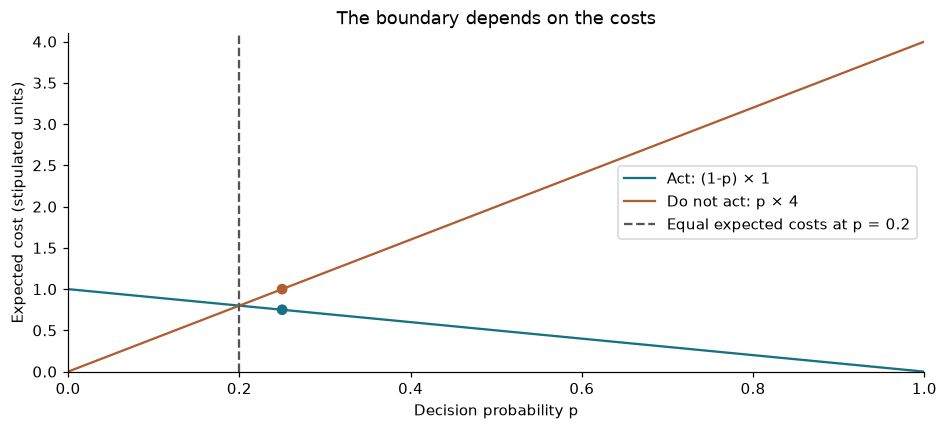

Saved fixed reference results to results.json in the output folder.


In [6]:
p_grid = np.linspace(0, 1, 301)
fig, ax = plt.subplots(figsize=(8.5, 3.8), layout="constrained")
ax.plot(p_grid, 1-p_grid, label="Act: (1-p) × 1", color="#167184")
ax.plot(p_grid, 4*p_grid, label="Do not act: p × 4", color="#ae5e32")
ax.axvline(0.2, ls="--", color="#555555", label="Equal expected costs at p = 0.2")
ax.scatter([0.25, 0.25], [0.75, 1.0], color=["#167184", "#ae5e32"], zorder=3)
ax.set(xlabel="Decision probability p", ylabel="Expected cost (stipulated units)",
       xlim=(0, 1), ylim=(0, 4.1), title="The boundary depends on the costs")
ax.legend()
show_figure(fig, "expected_costs")

results = {"expected_counts": counts, "ppv_by_prevalence": dict(zip(map(str, prevalences), map(float, ppvs))),
           "decision_at_p_0.25": decision_example, "costs": {"false_positive": 1, "false_negative": 4}}
written = (OUTPUT / "results.json").write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")

print("Saved fixed reference results to results.json in the output folder.")


### What these two thresholds mean

The **classifier operating threshold** defines positive and negative labels and therefore the sensitivity and specificity used in the counts. The **decision threshold** compares actions after a probability has been supplied. Changing a cost slider changes the latter; it does not retrain a classifier or supply a new sensitivity/specificity pair.

**Calibration** concerns whether cases assigned probabilities near, for example, 0.2 have the condition about 20% of the time in the intended population. This notebook supplies probabilities rather than estimating or checking calibration from data. A mathematically correct threshold cannot repair an unsupported probability. The cost model also omits harms of correct actions, delays, repeated tests, competing outcomes and patient-specific preferences. Those omissions should be addressed when defining an actual decision problem.


## 4. Interactive experiment: change one assumption

The left controls change the expected 10,000-person table. The right controls change the separate decision example. **Decision probability p stays independent of the PPV display:** changing prevalence does not silently replace p with a group average. To study a policy using only a positive label, explicitly set p to that group's displayed PPV and explain the information being discarded.

Try raising specificity from 90% to 99% at 1% prevalence, keeping sensitivity fixed. Next keep p fixed and change only the false-negative cost. Predict which panel should change. Controls update on release; the figures above retain the paper's fixed reference inputs. A PPV marked undefined means no positive group exists under the selected rates.


In [7]:
import ipywidgets as widgets
from IPython.display import HTML

def slider(value, low, high, step, description):
    return widgets.FloatSlider(value=value, min=low, max=high, step=step,
                               description=description, continuous_update=False,
                               style={"description_width": "145px"},
                               layout=widgets.Layout(width="355px"))

controls = {
    "prevalence_pct": slider(1, 0, 100, 0.1, "Prevalence (%)"),
    "sensitivity_pct": slider(90, 0, 100, 1, "Sensitivity (%)"),
    "specificity_pct": slider(90, 0, 100, 0.1, "Specificity (%)"),
    "p": slider(0.25, 0, 1, 0.01, "Decision p"),
    "c_fp": slider(1, 0.1, 10, 0.1, "False-positive cost"),
    "c_fn": slider(4, 0.1, 10, 0.1, "False-negative cost"),
}
dashboard_state = {}

def update_dashboard(prevalence_pct, sensitivity_pct, specificity_pct, p, c_fp, c_fn):
    c = expected_counts(prevalence_pct/100, sensitivity_pct/100, specificity_pct/100)
    group_ppv = positive_predictive_value(c)
    decision = compare_costs(p, c_fp, c_fn)
    dashboard_state.clear()
    dashboard_state.update(counts=c, ppv=group_ppv, p=p, decision=decision)
    ppv_text = f"{group_ppv:.2%}" if math.isfinite(group_ppv) else "undefined (no positive results)"
    display(HTML(f"<p><b>Positive group:</b> TP = {c['TP']:,.1f}; FP = {c['FP']:,.1f}; "
                 f"PPV = {ppv_text}.<br><b>Separate decision:</b> p = {p:.2f}; "
                 f"boundary = {decision['threshold']:.3f}; {decision['preferred']}.</p>"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
    axes[0].bar(["Positive", "Negative"], [c["TP"], c["FN"]],
                label="Condition present", color="#167184")
    axes[0].bar(["Positive", "Negative"], [c["FP"], c["TN"]], bottom=[c["TP"], c["FN"]],
                label="Condition absent", color="#ae5e32")
    axes[0].set(ylabel="Expected people per 10,000", title="Classification counts")
    axes[0].legend(fontsize=8)
    axes[1].plot(p_grid, (1-p_grid)*c_fp, color="#167184", label="Act")
    axes[1].plot(p_grid, p_grid*c_fn, color="#ae5e32", label="Do not act")
    axes[1].axvline(decision["threshold"], color="#555555", ls="--", label="Cost boundary")
    axes[1].scatter([p, p], [decision["act"], decision["no_act"]],
                    color=["#167184", "#ae5e32"], zorder=3)
    axes[1].set(xlabel="Decision probability p", ylabel="Expected cost", xlim=(0, 1),
                title="Stipulated two-action costs")
    axes[1].legend(fontsize=8)
    plt.show()
    plt.close(fig)

live_output = widgets.interactive_output(update_dashboard, controls)
classification_controls = widgets.VBox([widgets.HTML("<b>Population and fixed test rates</b>"),
                                         *(controls[k] for k in ("prevalence_pct", "sensitivity_pct", "specificity_pct"))])
decision_controls = widgets.VBox([widgets.HTML("<b>Separate probability and costs</b>"),
                                  *(controls[k] for k in ("p", "c_fp", "c_fn"))])
dashboard = widgets.VBox([widgets.Box([classification_controls, decision_controls],
                            layout=widgets.Layout(display="flex", flex_flow="row wrap")), live_output])
display(dashboard)


### Check that the controls keep the questions separate

These checks change a test rate, a cost and an empty-positive-group case through the actual widget callbacks. The original slider settings are restored afterwards. Read the assertions as predictions about which quantities should stay fixed.


In [8]:
original_controls = {name: control.value for name, control in controls.items()}
try:
    for name, value in dict(prevalence_pct=1, sensitivity_pct=90, specificity_pct=90,
                            p=0.25, c_fp=1, c_fn=4).items():
        controls[name].value = value
    assert math.isclose(dashboard_state["ppv"], 1/12)
    before_decision = dict(dashboard_state["decision"])
    controls["specificity_pct"].value = 99
    assert math.isclose(dashboard_state["ppv"], 90/189)
    assert dashboard_state["decision"] == before_decision
    before_counts = dict(dashboard_state["counts"])
    controls["c_fn"].value = 2
    assert dashboard_state["decision"]["preferred"] == "do not act"
    assert dashboard_state["counts"] == before_counts
    controls["prevalence_pct"].value = 0
    controls["specificity_pct"].value = 100
    assert math.isnan(dashboard_state["ppv"])
    controls["c_fn"].value = 4
    controls["p"].value = 0.2
    assert dashboard_state["decision"]["preferred"] == "equal expected cost"
finally:
    for name, value in original_controls.items():
        controls[name].value = value
print("PASS: live callbacks, independent population/decision controls, undefined PPV and cost equality; original controls restored.")


PASS: live callbacks, independent population/decision controls, undefined PPV and cost equality; original controls restored.


## 5. Exercises and worked reasoning

1. **Biomedical/imaging:** double the population while holding prevalence, sensitivity and specificity fixed. Explain which quantities change. Then raise specificity from 90% to 99% at 1% prevalence: does PPV exceed 50%?
2. **Computational:** at 1% prevalence and 90% sensitivity, derive the specificity needed for PPV to exceed 50%. Check your boundary by substitution.
3. **Both paths:** keep $p=0.25$. Compare costs $(C_{\mathrm{FP}},C_{\mathrm{FN}})=(1,4)$, $(10,40)$ and $(1,2)$. Which change alters the preferred action? Name a measurement and a value judgment still needed before using such a rule in practice.

<details><summary><strong>Show reasoning</strong></summary>

1. Every expected count doubles; PPV and the separate decision calculation stay fixed. At 99% specificity, expected true positives remain 90 and false positives become 99. PPV is $90/189\approx47.6\%$, below 50%.
2. More true than false positives requires $0.9(0.01)>(1-\mathrm{Sp})(0.99)$, so $\mathrm{Sp}>1-0.009/0.99\approx0.990909$. Equality gives exactly 50% PPV; exceeding it requires specificity above about 99.09%. Estimated rates would additionally need uncertainty assessment.
3. The first boundary is 0.2, and the second is also 0.2: multiplying both costs by ten rescales losses without changing their ordering. Reducing the false-negative cost to 2 raises the boundary to $1/3$, so $p=0.25$ now favours not acting. Probability calibration in the intended population needs evidence; choosing and justifying consequences requires patient and clinical values as well as measurements.

</details>

**Takeaway:** PPV follows from a defined population and classification rule; a decision additionally needs an appropriate probability and justified consequences.

**Check your understanding:** if two systems have the same PPV, must they identify the same people or support the same clinical action? State the extra information needed for each claim.


In [9]:
assert math.isclose(positive_predictive_value(expected_counts(0.01, 0.9, 0.99)), 90/189)
specificity_boundary = 1 - 0.9*0.01/0.99
assert math.isclose(positive_predictive_value(expected_counts(0.01, 0.9, specificity_boundary)), 0.5)
assert positive_predictive_value(expected_counts(0.01, 0.9, 0.995)) > 0.5
assert compare_costs(0.25, 1, 2)["preferred"] == "do not act"
print(f"Exercise checks passed; specificity boundary = {specificity_boundary:.6%}.")


Exercise checks passed; specificity boundary = 99.090909%.


## Further reading and connections

- Gigerenzer and Hoffrage (1995), [*How to Improve Bayesian Reasoning Without Instruction: Frequency Formats*](https://pure.mpg.de/pubman/item/item_2543495_7/component/file_2562163/GG_How_1995.pdf), studies how presenting information as frequencies affects Bayesian reasoning. The arithmetic above is derived directly from the stipulated rates.
- Guo et al. (2017), [*On Calibration of Modern Neural Networks*](https://proceedings.mlr.press/v70/guo17a.html), investigates calibration and post-processing methods. Calibration is a separate empirical question from computing PPV under given rates.
- [00: levels of explanation](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/00_intro_timeline.ipynb), [09: segmentation and interpretation](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/09_segmentation_reflection.ipynb) and [11: shortcut dependence](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/11_shortcut_dependence.ipynb) ask how a target, reference and population affect an evaluation. The paper's “Prediction acquires meaning inside a decision” section supplies the shared interpretation.
